## Drop Column feature ranking (4.1.2)

This file calculates the top N SBP and DBP features using the drop column approach for both the subject independent and dependent modes.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, GroupKFold
from collections import defaultdict
import os

In [35]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")

In [36]:
def load_all_data():
    """
    Load and combine all pre-split folds into one dataset
    
    The original dataset comes pre-split into 5 folds, but I combine them so I can split using
    groups over the patient id
    """
    all_folds = []
    for fold_num in range(5):
        fold_data = load_data(fold_num)
        all_folds.append(fold_data)
    
    combined = pd.concat(all_folds, ignore_index=True)
    print(f"Combined dataset shape: {combined.shape}")
    print(f"Total samples: {len(combined)}")
    
    return combined

def prepare_data(data):
    '''
    Extract the targets, features and patient ID's (groups) from the dataset

    Structure of data: 
    - Column 0: patient (used to in GroupKFold to prevent patient leakage)
    - Column 1: trial
    - Column 2: SBP
    - Column 3: DBP
    - Columns 4+: features
    '''
    y_SBP = data.iloc[:,2].values
    y_DBP = data.iloc[:,3].values
    X = data.iloc[:,4:]
    groups = data.iloc[:, 0].values

    print(f"\nDataset summary:")
    print(f"    Features: {X.shape[1]}")
    print(f"    Samples: {len(X)}")
    print(f"    Unique patients: {len(np.unique(groups))}")
    print(f"    SBP range: [{y_SBP.min():.4f}, {y_SBP.max():.4f}]")
    print(f"    DBP range: [{y_DBP.min():.4f}, {y_DBP.max():.4f}]")

    return y_SBP, y_DBP, X, groups


In [37]:
def train_baseline_model(X_train, y_train, seed, N_ESTIMATORS):
    '''
    Train an RF using all features
    '''
    model = RandomForestRegressor(
        n_estimators=N_ESTIMATORS,
        random_state=seed,
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    return model

In [38]:
def compute_drop_column_importance(X_train, X_val, y_train, y_val, feature_cols, baseline_error, seed, N_ESTIMATORS):
    '''
    For each feature:
    1. Remove it from the train and test sets
    2. Train a new RF model without it
    3. Measure the increase/decrease in error => larger increase is equal to more importance
    '''
    importance_scores = {}
    
    for i, feature in enumerate(feature_cols, 1):
        if i % 10 == 0:
            print(f'Progress: {i}/{len(feature_cols)} features')

        X_train_drop = X_train.drop(columns=feature)
        X_val_drop = X_val.drop(columns=feature)
        
        model = RandomForestRegressor(
            n_estimators=N_ESTIMATORS,
            random_state=seed,
            n_jobs=-1
        )
        model.fit(X_train_drop, y_train)

        # Measure error increase
        y_pred = model.predict(X_val_drop)
        mae_drop = mean_absolute_error(y_val, y_pred)

        importance_scores[feature] = mae_drop - baseline_error
        
    return importance_scores

In [39]:
def print_results(results):
    """Print results for each CV mode"""
    
    print(f'\n{"="*70}')
    print('FINAL RESULTS')
    
    for mode in ["subject_dependent", "subject_independent"]:
        print(f'\n{"="*70}')
        print(f'MODE: {mode.upper().replace("_", " ")}')
        print(f'{"="*70}')
        
        for target in ["SBP", "DBP"]:
            print(f'Target: {target}')
            
            importance = results[mode][target]
            
            # Normalize and get cumulative importance
            importance_norm = importance / importance.sum()
            importance_sorted = importance_norm.sort_values(ascending=False)
            cumulative = importance_sorted.cumsum()
            
            # Features covering 66%
            threshold_idx = (cumulative <= 0.66).sum()
            if threshold_idx == 0:
                threshold_idx = 1
            top_features = importance_sorted.iloc[:threshold_idx]
            
            print(f'\nTop {len(top_features)} features covering 66% importance:')
            for i, (feat, norm_imp) in enumerate(top_features.items(), 1):
                abs_imp = importance[feat]
                print(f'  {i:2d}. {feat:40s} {norm_imp:8.4f} (abs: {abs_imp:.6f})')
            
            print(f'\nTop 30 by absolute importance:')
            for i, (feat, imp) in enumerate(importance.head(30).items(), 1):
                print(f'  {i:2d}. {feat:40s} {imp:.6f}')

In [40]:
def plot_results(results, TOP_N_FEATURES, output_folder='FeatureRanking_Results'):

    os.makedirs(output_folder, exist_ok=True)
    
    print(f'\n{"="*70}')
    print('GENERATING PLOTS')
    print(f'{"="*70}')
    
    for mode in ["subject_dependent", "subject_independent"]:
        fig, axes = plt.subplots(1, 2, figsize=(16, 8))
        
        # SBP plot
        sbp_top = results[mode]["SBP"].sort_values(ascending=True).tail(TOP_N_FEATURES)
        sbp_top.plot.barh(ax=axes[0], color="skyblue", edgecolor='navy', linewidth=0.5)
        axes[0].set_title(
            f'Top {TOP_N_FEATURES} Features for SBP\n'
            f'{mode.replace("_", " ").title()} CV',
            fontsize=14, fontweight='bold'
        )
        axes[0].set_xlabel('Increase in MAE', fontsize=12)
        axes[0].set_ylabel('Feature', fontsize=12)
        axes[0].axvline(x=0, color='red', linestyle='--', linewidth=1, alpha=0.7)
        axes[0].grid(axis='x', alpha=0.3)
        
        # DBP plot
        dbp_top = results[mode]["DBP"].sort_values(ascending=True).tail(TOP_N_FEATURES)
        dbp_top.plot.barh(ax=axes[1], color="lightgreen", edgecolor='darkgreen', linewidth=0.5)
        axes[1].set_title(
            f'Top {TOP_N_FEATURES} Features for DBP\n'
            f'{mode.replace("_", " ").title()} CV',
            fontsize=14, fontweight='bold'
        )
        axes[1].set_xlabel('Increase in MAE', fontsize=12)
        axes[1].set_ylabel('Feature', fontsize=12)
        axes[1].axvline(x=0, color='red', linestyle='--', linewidth=1, alpha=0.7)
        axes[1].grid(axis='x', alpha=0.3)
        
        plt.tight_layout()
        
        filename = os.path.join(output_folder, f'FeatureRanking_DropColumn_{mode}.png')
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        plt.show()

Combined dataset shape: (3063, 222)
Total samples: 3063

Dataset summary:
    Features: 218
    Samples: 3063
    Unique patients: 40
    SBP range: [71.7483, 191.0738]
    DBP range: [44.4748, 100.6747]
running mode subject_dependent
running seed 42
fold number: 1 / 5
Train size: 2450, Val size: 613
Training SBP baseline
Calculating drop column importance for SBP
Progress: 10/218 features
Progress: 20/218 features
Progress: 30/218 features
Progress: 40/218 features
Progress: 50/218 features
Progress: 60/218 features
Progress: 70/218 features
Progress: 80/218 features
Progress: 90/218 features
Progress: 100/218 features
Progress: 110/218 features
Progress: 120/218 features
Progress: 130/218 features
Progress: 140/218 features
Progress: 150/218 features
Progress: 160/218 features
Progress: 170/218 features
Progress: 180/218 features
Progress: 190/218 features
Progress: 200/218 features
Progress: 210/218 features
Training DBP baseline...
Calculating drop column importance for SBP
Progres

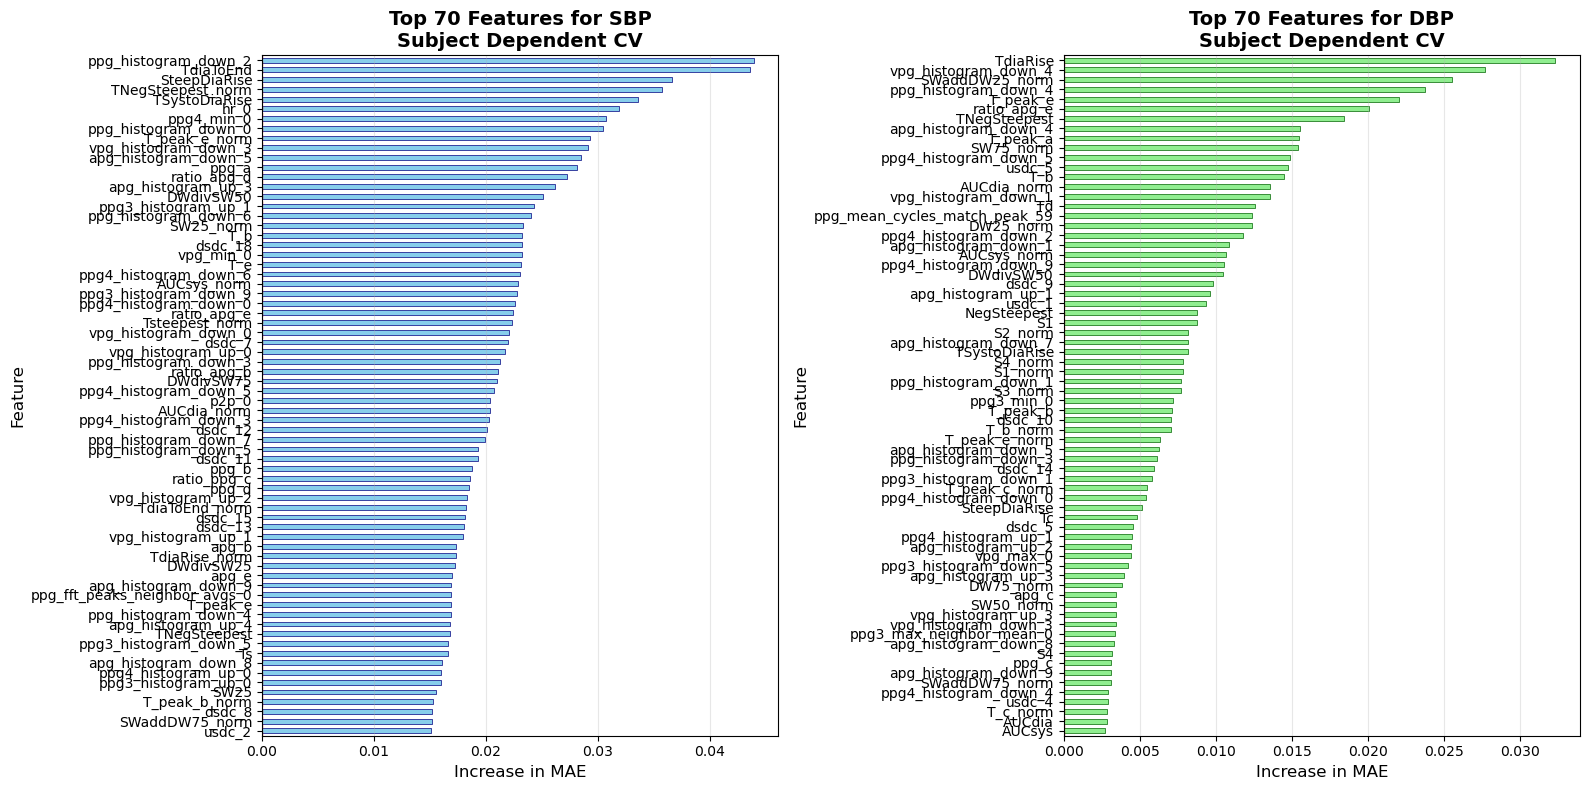

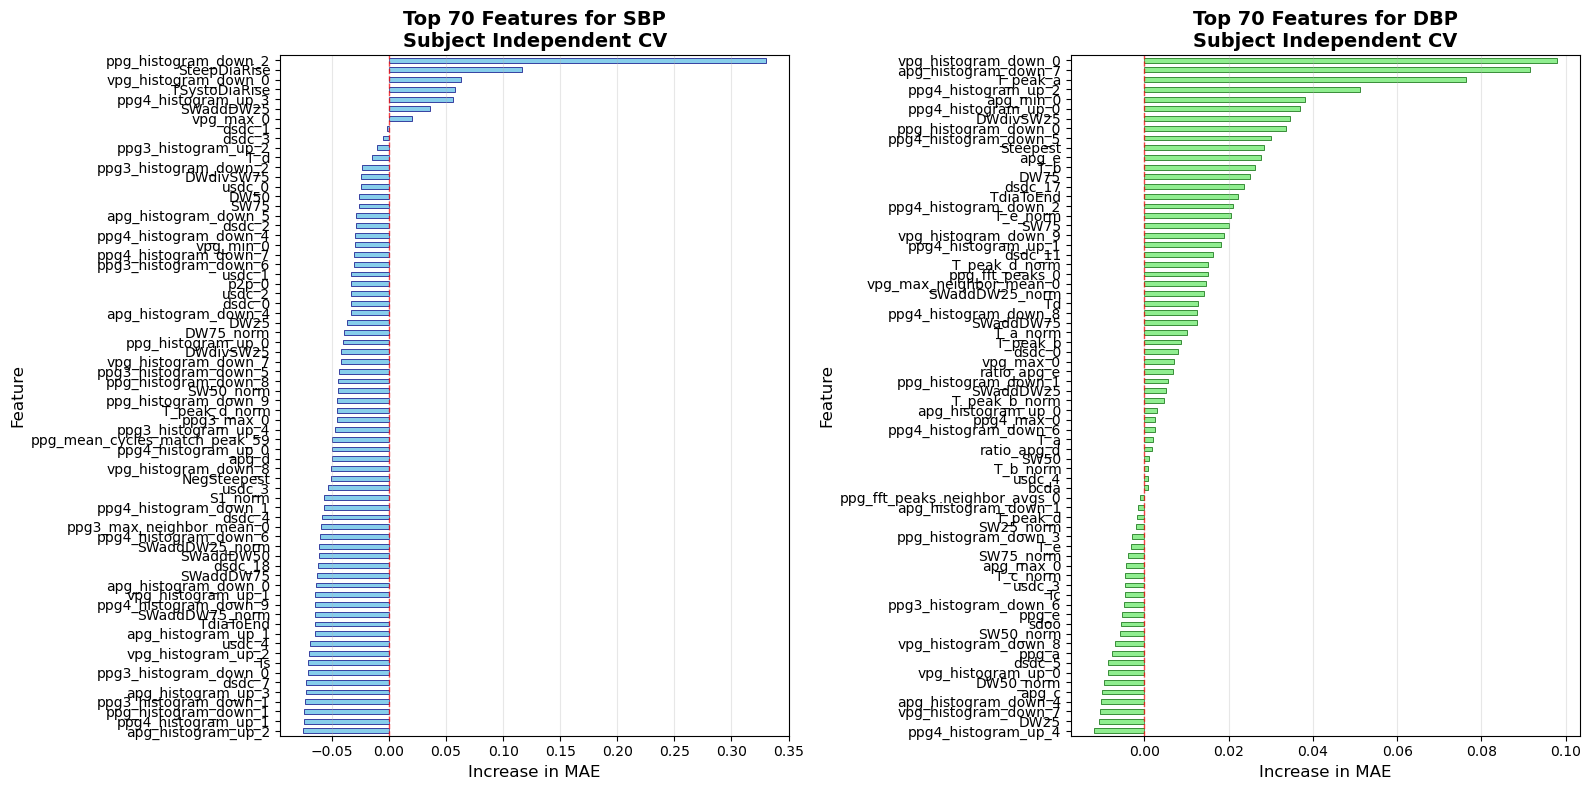

In [41]:
n_splits = 5
#seeds = [42,12,77]
seeds = [42]
N_ESTIMATORS = 50
TOP_N_FEATURES = 70  # Number of features to show in plots

combined_data = load_all_data()
y_SBP, y_DBP, X, groups = prepare_data(combined_data)
feature_cols = X.columns.tolist()

'''
2 CV strategies: subject leakage (same patients different heartbeats in train and test set) VS none

Subject Dependent: Tests how well features predict within the same patients (with data leakage)
Subject Independent: Tests how well features generalize to new, unseen patients (no data leakage)
'''
cv_strategies = {
    "subject_dependent": KFold(n_splits=n_splits, shuffle=True, random_state=42),
    "subject_independent": GroupKFold(n_splits=n_splits)
}

# Store results for each CV mode
results = {}

for mode, splitter in cv_strategies.items():
    print(f'running mode {mode}')

    importance_SBP = defaultdict(list)
    importance_DBP = defaultdict(list)

    for seed in seeds:
        print(f'running seed {seed}')

        # Create splits
        if mode == "subject_independent":
            splits = list(splitter.split(X, y_SBP, groups))
        else:
            splits = list(splitter.split(X, y_SBP))

        '''
        # GroupKFold needs groups, KFold does not
        split_args = (
            splitter.split(X, y_SBP, groups)
            if mode == "subject_independent"
            else splitter.split(X, y_SBP)
        )
        '''

        for fold, (train_idx, val_idx) in enumerate(splits, 1):
            print(f"fold number: {fold} / {n_splits}")

            X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
            y_SBP_train, y_SBP_val = y_SBP[train_idx], y_SBP[val_idx]
            y_DBP_train, y_DBP_val = y_DBP[train_idx], y_DBP[val_idx]

            # Check for patient leakage in subject_independent mode
            if mode == "subject_independent":
                train_patients = set(groups[train_idx])
                val_patients = set(groups[val_idx])
                assert len(train_patients & val_patients) == 0, "Patient leakage detected!"
                print(f'Train patients: {len(train_patients)}, Val patients: {len(val_patients)}')
            
            print(f'Train size: {len(X_train)}, Val size: {len(X_val)}')

            # SBP Analysis
            print('Training SBP baseline')
            RF_SBP = train_baseline_model(X_train, y_SBP_train, seed, N_ESTIMATORS)
            baseline_error_SBP = mean_absolute_error(
                y_SBP_val, RF_SBP.predict(X_val)
            )
            print('Calculating drop column importance for SBP')
            fold_importance_SBP = compute_drop_column_importance(
                    X_train, X_val, y_SBP_train, y_SBP_val,
                    feature_cols, baseline_error_SBP, seed, N_ESTIMATORS
                )
            
            # DBP Analysis
            print('Training DBP baseline...')
            RF_DBP = train_baseline_model(X_train, y_DBP_train, seed, N_ESTIMATORS)
            baseline_error_DBP = mean_absolute_error(
                y_DBP_val, RF_DBP.predict(X_val)
            )
            print('Calculating drop column importance for SBP')
            fold_importance_DBP = compute_drop_column_importance(
                X_train, X_val, y_DBP_train, y_DBP_val,
                feature_cols, baseline_error_DBP, seed, N_ESTIMATORS
            )

            for feature in feature_cols:
                importance_SBP[feature].append(fold_importance_SBP[feature])
                importance_DBP[feature].append(fold_importance_DBP[feature])
    
    # aggregate
    results[mode] = {
            "SBP": pd.Series({
                f: np.mean(scores) for f, scores in importance_SBP.items()
            }).sort_values(ascending=False),
            
            "DBP": pd.Series({
                f: np.mean(scores) for f, scores in importance_DBP.items()
            }).sort_values(ascending=False)
        }
    
print_results(results)
plot_results(results, TOP_N_FEATURES)

## Save results

In [42]:
file_path = Path("FeatureRanking_Results/rf_results.pkl")

with open(file_path, "rb") as f:
    res = pickle.load(f)

res.update({
    "dropcol_folds": n_splits,
    "dropcol_seeds": seeds,
    "dropcol_n_estimator": N_ESTIMATORS,
    "dropcol_sbp_ranking": list(zip(
        results["subject_independent"]["SBP"].index,
        results["subject_independent"]["SBP"].values
    )),
    "dropcol_dbp_ranking": list(zip(
        results["subject_independent"]["DBP"].index,
        results["subject_independent"]["DBP"].values
    )),
    "dropcol_sbp_ranking_subject_dependent": list(zip(
        results["subject_dependent"]["SBP"].index,
        results["subject_dependent"]["SBP"].values
    )),
    "dropcol_dbp_ranking_subject_dependent": list(zip(
        results["subject_dependent"]["DBP"].index,
        results["subject_dependent"]["DBP"].values
    )),
})

with open(file_path, "wb") as f:
    pickle.dump(res, f)

print(f"Results saved to {file_path}")
print(f"Keys: {list(res.keys())}")

Results saved to FeatureRanking_Results/rf_results.pkl
Keys: ['folds', 'seeds', 'n_estimator', 'sbp_ranking', 'dbp_ranking', 'sbp_ranking_subject_dependent', 'dbp_ranking_subject_dependent', 'sbp_ranking_pearson_impurity_indep', 'dbp_ranking_pearson_impurity_indep', 'sbp_ranking_spearman_impurity_indep', 'dbp_ranking_spearman_impurity_indep', 'dropcol_folds', 'dropcol_seeds', 'dropcol_n_estimator', 'dropcol_sbp_ranking', 'dropcol_dbp_ranking', 'dropcol_sbp_ranking_subject_dependent', 'dropcol_dbp_ranking_subject_dependent']
